In [1]:
import pandas as pd
import glob
import os
import scanpy as sc

/software/cellgen/team298/ls34/cellphonedb/lib/python3.11/site-packages/scanpy/_utils/__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/software/cellgen/team298/ls34/cellphonedb/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/software/cellgen/team298/ls34/cellphonedb/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/software/cellgen/team298/ls34/cellphonedb/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  

In [2]:
from IPython.display import HTML, display
from cellphonedb.utils import db_releases_utils

display(HTML(db_releases_utils.get_remote_database_versions_html()['db_releases_html_table']))

In [3]:
#sc.settings.figdir = "fig5"


In [4]:
sc.settings.set_figure_params(dpi_save=300, dpi=300, facecolor="white", frameon=False, figsize=(20,20))


In [5]:
os.getcwd()

'/nfs/users/nfs_l/ls34/mintflow-reproducibility/analysis/atopic_dermatitis'

In [6]:
cpdb_version = 'v5.0.0'

# -- Path where the input files to generate the database are located
cpdb_target_dir = os.path.join('/nfs/team298/ls34/adult_skin/cellphonedb/', cpdb_version)

In [7]:
from cellphonedb.utils import db_utils

db_utils.download_database(cpdb_target_dir, cpdb_version)

Downloaded cellphonedb.zip into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/sources


In [8]:
cpdb_input_dir = '/nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/'


In [9]:
from cellphonedb.utils import db_utils

# -- Creates new database
db_utils.create_db(cpdb_input_dir)


Created /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/cellphonedb_11_09_2026_032414.zip successfully


In [10]:
# %%bash

# mv /nfs/team298/ls34/cellphonedb/v5.0.0/cellphonedb_09_28_2024_123936.zip /nfs/team298/ls34/cellphonedb/v5.0.0/cellphonedb.zip

In [11]:
pd.set_option('display.max_columns', 100)

In [12]:
os.listdir(cpdb_target_dir)

['complex_input.csv',
 'cellphonedb_11_29_2025_151752.zip',
 'cellphonedb_06_27_2025_102937.zip',
 'cellphonedb_06_26_2025_080404.zip',
 'results',
 'gene_input.csv',
 'cellphonedb.zip',
 'cellphonedb_11_09_2026_032414.zip',
 'cellphonedb_11_09_2026_031548.zip',
 'sources',
 'interaction_input.csv',
 'cellphonedb_11_08_2026_081630.zip',
 'cellphonedb_06_27_2025_160210.zip',
 'cellphonedb_06_26_2025_101630.zip',
 'cellphonedb_06_27_2025_141818.zip',
 'cellphonedb_06_26_2025_075952.zip',
 'cellphonedb_06_27_2025_153425.zip',
 'cellphonedb_06_26_2025_114324.zip',
 'cellphonedb_11_29_2025_143413.zip',
 'protein_input.csv',
 'cellphonedb_11_29_2025_153946.zip',
 'cellphonedb_11_29_2025_122618.zip']

In [13]:
cpdb_file_path = os.path.join(cpdb_target_dir, 'cellphonedb.zip')
cpdb_file_path




'/nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/cellphonedb.zip'

In [14]:
meta_file_path = '/nfs/team298/ls34/adult_skin/cellphonedb/input_files/metadata_all.tsv'

In [15]:
out_path = '/nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore'


In [16]:
metadata = pd.read_csv(meta_file_path, sep = '\t')
metadata.head(3)

,barcode_sample,cell_type
0,GCTGCAGCAGCCGTCA_GSM5277185,F2: Universal
1,CAAGAAAGTACTCTCC_GSM5264341,F4: DS_DPEP1+
2,AGATCGTAGATCCCAT_GSM4815804,Th


In [17]:
metadata.cell_type.value_counts()

cell_type
F2: Universal                     4460
F1: Superficial                   3022
VE3_Ven                           2743
F2/3: Perivascular                2308
Th                                2226
F3: FRC-like                      1996
Pericyte1                         1697
Mac2_CCL14hi                      1429
Mast cell                         1383
Melanocyte                        1322
Th_PPARGhi                        1215
LE                                1024
LC                                1003
cDC2: EREG+CCR7+                   895
F4: DS_DPEP1+                      890
Treg_LRRC32+                       866
cDC2: MMP12hi                      721
Tc2                                662
F4: TNN+COCH+                      644
Treg                               551
VE1_Art                            538
TRM_IL13+                          513
cDC1                               498
cDC2                               478
T_γδ                               432
Mac2           

In [18]:
import anndata
counts_file_path = '/nfs/team298/ls34/adult_skin/cellphonedb/input_files/normalised_log_counts_all.h5ad'
adata = anndata.read_h5ad(counts_file_path)
adata.shape

(37364, 32732)

In [19]:
list(adata.obs.index).sort() == list(metadata['barcode_sample']).sort()


True

In [20]:
# KEEP_LIST = [#'Melanocyte',
#  #'KC3',
#  #'Sweat gland',
#  'Pericyte1_CCL19+_signalling',
#  'VE3_SELPhi',
#  'LE',
#  #'Sweat gland channel inner',
#  'VE1_ADAMTS6hi',
#  'F3: CCL19+',
#  'cDC1',
#  'Pericyte2_CASQ2_Muscle',
#  #'Sweat gland channel outer',
#  'nmSchwann',
#  'Mac2',
#  'F2/3: Bridge',
#  'F1: Superficial',
#  'LC',
#  'F2: Universal',
#  'F5: NGFR+',
#  'cDC2: IL1B+',
# # 'F4: TNN+COCH+',
#  'F1: Superficial regenerative',
#  #'Cartilage',
#  'cDC2: MMP12+',
#  #'KC_HF/SC: LGR6+ACTA2+',
#  'F5: RAMP1+',
#  'MigDC',
# # 'F4: DS_DPEP1+',
#  #'mSchwann',
#  #'KC1',
#  'ILC1_3',
#  'Plasma cell',
#  'MoDC',
#  'F6: Myofibroblast inflammatory',
#  #'pDC',
#  'Tc_IFNGhi',
#  #'Smooth muscle',
#  #'Bcell',
#  'Tc_IL13',
#  #'F4: DP_HHIP+',
#  'Treg',
#  'ILC2_inflammatory',
#  'Th',
#  'Tc',
# # 'KC_Sebocyte_basal',
# # 'KC_Sebocyte_inner',
#  'VE2',
#  #'Mono',
#  #'MacTREM2_CX3CR1+',
#  'NK',
#  'ILC1_NK',
#  'Tc_gamma_delta',
#  'Tr1',
#  'Mast cell',
#  'Tnaive/Tcm',
#  #'KC4',
#  #'KC2/3_cycling',
#  #'KC2',
#  #'KCinflamm_basal',
#  #'KCinflamm_int',
#  #'KC5',
#  'ILC2',
#  #'KC_HF: ORS/CL',
#  #'KC_HF: Basal_LGR5+',
#  #'F_Fascia',
#  #'Merkel cell',
#  #'KC_HF: Basal_NPNT+',
#  #'Mono CD16+',
#  #'KC_HF: IRS+HS',
#  'Mac1',
#  #'KCinflamm_late',
#  #'KCinflamm_cycling',
#  'Tc_IL17',
#  #'Satellite muscle',
#  #'Adipocyte',
#  #'Neutrophil',
#  #'Skeletal muscle'
# ]
# KEEP_LIST

In [21]:
from cellphonedb.src.core.methods import cpdb_statistical_analysis_method

cpdb_results = cpdb_statistical_analysis_method.call(
    cpdb_file_path = cpdb_file_path,                 # mandatory: CellphoneDB database zip file.
    meta_file_path = meta_file_path,                 # mandatory: tsv file defining barcodes to cell label.
    counts_file_path = counts_file_path,             # mandatory: normalized count matrix - a path to the counts file, or an in-memory AnnData object
    counts_data = 'hgnc_symbol',                     # defines the gene annotation in counts matrix.
    #active_tfs_file_path = active_tf_path,           # optional: defines cell types and their active TFs.
    #microenvs_file_path = microenvs_file_path,       # optional (default: None): defines cells per microenvironment.
    score_interactions = True,                       # optional: whether to score interactions or not. 
    iterations = 1000,                               # denotes the number of shufflings performed in the analysis.
    threshold = 0.1,                                 # defines the min % of cells expressing a gene for this to be employed in the analysis.
    threads = 5,                                     # number of threads to use in the analysis.
    debug_seed = 42,                                 # debug randome seed. To disable >=0.
    result_precision = 3,                            # Sets the rounding for the mean values in significan_means.
    pvalue = 0.05,                                   # P-value threshold to employ for significance.
    subsampling = False,                             # To enable subsampling the data (geometri sketching).
    subsampling_log = False,                         # (mandatory) enable subsampling log1p for non log-transformed data inputs.
    subsampling_num_pc = 100,                        # Number of componets to subsample via geometric skectching (dafault: 100).
    subsampling_num_cells = 1000,                    # Number of cells to subsample (integer) (default: 1/3 of the dataset).
    separator = '|',                                 # Sets the string to employ to separate cells in the results dataframes "cellA|CellB".
    debug = False,                                   # Saves all intermediate tables employed during the analysis in pkl format.
    output_path = out_path,                          # Path to save results.
    output_suffix = None                             # Replaces the timestamp in the output files by a user defined string in the  (default: None).
    )

Reading user files...
The following user files were loaded successfully:
/nfs/team298/ls34/adult_skin/cellphonedb/input_files/normalised_log_counts_all.h5ad
/nfs/team298/ls34/adult_skin/cellphonedb/input_files/metadata_all.tsv
[ ][CORE][09/11/26-03:24:29][INFO] [Cluster Statistical Analysis] Threshold:0.1 Iterations:1000 Debug-seed:42 Threads:5 Precision:3
[ ][CORE][09/11/26-03:24:29][WARNING] Debug random seed enabled. Set to 42
[ ][CORE][09/11/26-03:24:31][INFO] Running Real Analysis
[ ][CORE][09/11/26-03:24:31][INFO] Running Statistical Analysis


100%|██████████| 1000/1000 [13:00<00:00,  1.28it/s]

[ ][CORE][09/11/26-03:37:32][INFO] Building Pvalues result


[ ][CORE][09/11/26-03:37:37][INFO] Building results
[ ][CORE][09/11/26-03:37:38][INFO] Scoring interactions: Filtering genes per cell type..


100%|██████████| 52/52 [00:00<00:00, 66.22it/s]

[ ][CORE][09/11/26-03:37:39][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..



100%|██████████| 52/52 [00:00<00:00, 269.56it/s]


[ ][CORE][09/11/26-03:37:39][INFO] Scoring interactions: Calculating scores for all interactions and cell types..


100%|██████████| 2704/2704 [07:04<00:00,  6.37it/s]


Saved deconvoluted to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_deconvoluted_11_09_2026_034449.txt
Saved deconvoluted_percents to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_deconvoluted_percents_11_09_2026_034449.txt
Saved means to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_means_11_09_2026_034449.txt
Saved pvalues to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_pvalues_11_09_2026_034449.txt
Saved significant_means to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_significant_means_11_09_2026_034449.txt
Saved interaction_scores to /nfs/team298/ls34/adult_skin/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_interaction_scores_11_09_2026_034449.txt


# analysis

In [22]:
import os
import anndata as ad
import pandas as pd
import ktplotspy as kpy
import matplotlib.pyplot as plt
%matplotlib inline

In [23]:
import os
os.listdir('/nfs/team298/ls34/wound/cellphonedb/v5.0.0/results/method2_withScore/')

['statistical_analysis_interaction_scores_04_27_2025_102032.txt',
 'statistical_analysis_significant_means_07_14_2025_150347.txt',
 'statistical_analysis_interaction_scores_02_11_2025_164652.txt',
 'statistical_analysis_interaction_scores_07_13_2025_151857.txt',
 'statistical_analysis_deconvoluted_10_05_2025_111229.txt',
 'statistical_analysis_pvalues_01_07_2026_171930.txt',
 'statistical_analysis_means_07_20_2025_120846.txt',
 'statistical_analysis_deconvoluted_05_19_2025_161057.txt',
 'statistical_analysis_means_04_27_2025_102032.txt',
 'statistical_analysis_means_02_11_2025_200835.txt',
 'statistical_analysis_pvalues_07_13_2025_144935.txt',
 'statistical_analysis_means_04_24_2025_103010.txt',
 'statistical_analysis_significant_means_02_11_2025_133108.txt',
 'statistical_analysis_significant_means_09_23_2025_152529.txt',
 'statistical_analysis_pvalues_01_09_2026_113751.txt',
 'statistical_analysis_deconvoluted_07_20_2025_120846.txt',
 'statistical_analysis_pvalues_09_24_2025_093053.t

In [24]:
1

1

In [25]:
# cpdb_results.results

In [26]:
try:
    decon=cpdb_results['deconvoluted']
    deconv=cpdb_results['deconvoluted']
    means = cpdb_results['means']
    pvals = cpdb_results['pvalues']
    interaction_scores=cpdb_results['interaction_scores']
    print("instantantiated")
except:
    print("not loaded")
    
    deconv = pd.read_csv("/nfs/team298/ls34/wound/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_deconvoluted_10_09_2024_201259.txt",  sep="\t")
    means = pd.read_csv('/nfs/team298/ls34/wound/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_means_10_09_2024_201259.txt', sep="\t")
    pvals = pd.read_csv("/nfs/team298/ls34/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_pvalues_10_09_2024_201259.txt", sep="\t")
    interaction_scores=pd.read_csv("/nfs/team298/ls34/cellphonedb/v5.0.0/results/method2_withScore/statistical_analysis_interaction_scores_10_09_2024_201259.txt", sep="\t")
    import anndata
    counts_file_path = '/nfs/team298/ls34/wound/cellphonedb/input_files/normalised_log_counts.h5ad'
    adata = anndata.read_h5ad(counts_file_path)
    adata.shape
    
 # statistical_analysis_deconvoluted_percents_10_09_2024_201259.txt
#5.2M -rw-r--r-- 1 ls34 team298  21M Oct  9 20:13 
#1.8M -rw-r--r-- 1 ls34 team298  19M Oct  9 20:13 
#768K -rw-r--r-- 1 ls34 team298 5.2M Oct  9 20:13 statistical_analysis_significant_means_10_09_2024_201259.txt
 

instantantiated


In [27]:
try:
    kpy.plot_cpdb_heatmap(pvals = pvals,
                      degs_analysis = False,
                      figsize = (20,20),
                      title = "Sum of significant interactions")
except:
    1

In [28]:

# kpy.plot_cpdb_heatmap(
#     pvals=pvals, cell_types=["MigDC", "Tnaive/Tcm",], figsize=(4, 4), title="Sum of significant interactions"
# )

In [29]:
# kpy.plot_cpdb(
#     adata = adata,
#     cell_type1 = "PV MYH11|PV STEAP4|PV MMPP11",
#     cell_type2 = "EVT_1|EVT_2|GC|iEVT|eEVT|VCT_CCC",
#     means = cpdb_results['means'],
#     pvals = cpdb_results['pvalues'],
#     celltype_key = "cell_labels",
#     genes = ["TGFB2", "CSF1R"],
#     figsize = (10, 3),
#     title = "Interactions between\nPV and trophoblast",
#     max_size = 3,
#     highlight_size = 0.75,
#     degs_analysis = False,
#     standard_scale = True,
#     interaction_scores = cpdb_results['interaction_scores'],
#     scale_alpha_by_interaction_scores = True
# )

In [30]:
# gene_programme200 = ['CD3E',
#  'CXCR4',
#  'CYBA',
#  'CD4',
#  'CCR4',
#  'ITGB2',
#  'ADAM8',
#  'TNFRSF1B',
#  'PLEC',
#  'JAK3',
#  'IL2RG',
#  'FSCN1',
#  'CD5',
#  'SELPLG',
#  'ACAP1',
#  'ITGAL',
#  'IKZF1',
#  'CD247',
#  'CD83',
#  'CCL22',
#  'CCR7',
#  'CCL17',
#  'MYH9',
#  'RUNX3',
#  'CFLAR',
#  'BATF',
#  'ZAP70',
#  'LAMP3',
#  'ALOX15',
#  'UCP2',
#  'FOXP3',
#  'SEPTIN9',
#  'CCL19',
#  'GRK2',
#  'MIAT',
#  'CD6',
#  'TNFRSF18',
#  'IKZF3',
#  'TCF7',
#  'PIM2',
#  'IL21R',
#  'CTLA4',
#  'CD7',
#  'MSN',
#  'SLC2A3',
#  'TRAF1',
#  'RFTN1',
#  'FURIN',
#  'SH2D2A',
#  'SERPINB9']

In [31]:
# gene_programme200

In [32]:
# deconvoluted

In [33]:
from cellphonedb.utils import search_utils

search_results = search_utils.search_analysis_results(
   # query_cell_types_1 = ['F6: Inflammatory myofibroblast', ],  # List of cells 1, will be paired to cells 2 (list or 'All').
    #query_cell_types_2 = ['Neutrophil'],     # List of cells 2, will be paired to cells 1 (list or 'All').
  query_genes = ['CD3E',
 'CXCR4',
 'CYBA',
 'CD4',
 'CCR4',
 'ITGB2',
 'ADAM8',
 'TNFRSF1B',
 'PLEC',
 'JAK3',
 'IL2RG',
 'FSCN1',
 'CD5',
 'SELPLG',
 'ACAP1',
 'ITGAL',
 'IKZF1',
 'CD247',
 'CD83',
 'CCL22',
 'CCR7',
 'CCL17',
 'MYH9',
 'RUNX3',
 'CFLAR',
 'BATF',
 'ZAP70',
 'LAMP3',
 'ALOX15',
 'UCP2',
 'FOXP3',
 'SEPTIN9',
 'CCL19',
 'GRK2',
 'MIAT',
 'CD6',
 'TNFRSF18',
 'IKZF3',
 'TCF7',
 'PIM2',
 'IL21R',
 'CTLA4',
 'CD7',
 'MSN',
 'SLC2A3',
 'TRAF1',
 'RFTN1',
 'FURIN',
 'SH2D2A',
 'SERPINB9'],                                       # filter interactions based on the genes participating (list).
 #   query_interactions = ['CSF1_CSF1R'],                            # filter intereactions based on their name (list).
    significant_means = means,          # significant_means file generated by CellphoneDB.
    deconvoluted = deconv,                    # devonvoluted file generated by CellphoneDB.
    interaction_scores = interaction_scores,        # interaction score generated by CellphoneDB.
    query_minimum_score = 50,                                       # minimum score that an interaction must have to be filtered.
    separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
    long_format = True,                                             # converts the output into a wide table, removing non-significant interactions
   # query_classifications = ['Signaling by Transforming growth factor']
)
search_results=search_results[search_results["significant_mean"]>1]
search_results.head(50)

,interacting_pair,partner_a,partner_b,gene_a,gene_b,directionality,classification,interacting_cells,significant_mean
2022,CXCL12_CXCR4,simple:P48061,simple:P61073,CXCL12,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|Eosinophil,1.314
2023,CXCL14_CXCR4,simple:O95715,simple:P61073,CXCL14,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|Eosinophil,1.328
2355,CXCL12_CXCR4,simple:P48061,simple:P61073,CXCL12,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|ILC1,1.079
2356,CXCL14_CXCR4,simple:O95715,simple:P61073,CXCL14,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|ILC1,1.093
2797,CCL21_CCR7,simple:O00585,simple:P32248,CCL21,CCR7,Ligand-Receptor,Signaling by Chemokines,Bcell|MigDC (cDC1),1.462
2919,TNF_TNFRSF1B,simple:P01375,simple:P20333,TNF,TNFRSF1B,Ligand-Receptor,Signaling by Tumor necrosis factor,Bcell|Monocyte,1.123
3022,CXCL14_CXCR4,simple:O95715,simple:P61073,CXCL14,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|TR1,1.010
3058,CXCL12_CXCR4,simple:P48061,simple:P61073,CXCL12,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|TRM_IL13+,1.189
3059,CXCL14_CXCR4,simple:O95715,simple:P61073,CXCL14,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|TRM_IL13+,1.204
3280,CXCL12_CXCR4,simple:P48061,simple:P61073,CXCL12,CXCR4,Ligand-Receptor,Signaling by Chemokines,Bcell|Tc2,1.237


In [34]:
search_results["interacting_pair"].unique()


array(['CXCL12_CXCR4', 'CXCL14_CXCR4', 'CCL21_CCR7', 'TNF_TNFRSF1B',
       'ICAM1_ITGAL', 'CCL19_CCR7', 'SELPLG_SELE', 'CCL19_ACKR4',
       'C3_integrin_aMb2_complex', 'CCL19_CCRL2',
       'THY1_integrin_aXb2_complex', 'THY1_integrin_aMb2_complex',
       'CCL5_CCR4', 'LTA_TNFRSF1B', 'CCL22_CCR4', 'CCL22_DPP4',
       'CD86_CTLA4', 'ALCAM_CD6', 'ICAM1_integrin_aXb2_complex'],
      dtype=object)

In [35]:
interaction_subset = ['CXCL14_CXCR4', 'TNF_TNFRSF1B', 'IL4_IL4_receptor',
       'ICAM1_integrin_aMb2_complex', 'ICAM1_integrin_aXb2_complex',
       'CXCL12_CXCR4', 'TNFSF18_TNFRSF18', 'THY1_integrin_aXb2_complex',
       'THY1_integrin_aMb2_complex', 'CCL19_CCR7', 'CCL21_CCR7',
       'SELPLG_SELE', 'C3_integrin_aMb2_complex', 'CCL19_ACKR4',
       'CCL19_CCRL2', 'CD86_CTLA4', 'CCL22_CCR4', 'CCL22_DPP4',
       'CCL17_CCR4', 'CCL5_CCR4']

# means_subset = means[means.index.isin(interaction_subset)]
# pvals_subset = pvals[pvals.index.isin(interaction_subset)]
# deconvoluted_subset = deconvoluted[deconvoluted.index.isin(interaction_subset)]


In [36]:
deconvoluted = cpdb_results['deconvoluted']
means = cpdb_results['means']
pvals = cpdb_results['pvalues']


In [37]:
# deconvoluted

In [38]:
means_subset = means[means["interacting_pair"].isin(interaction_subset)]
pvals_subset = pvals[pvals["interacting_pair"].isin(interaction_subset)]
deconvoluted_subset = deconvoluted#[deconvoluted["interacting_pair"].isin(interaction_subset)]


In [39]:
means_subset

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,ASIC2+_Mechanoreceptor|Bcell,ASIC2+_Mechanoreceptor|Eosinophil,ASIC2+_Mechanoreceptor|F1: Superficial,ASIC2+_Mechanoreceptor|F2/3: Perivascular,ASIC2+_Mechanoreceptor|F2: Universal,ASIC2+_Mechanoreceptor|F3: FRC-like,ASIC2+_Mechanoreceptor|F4: DS_DPEP1+,ASIC2+_Mechanoreceptor|F4: TNN+COCH+,ASIC2+_Mechanoreceptor|F5: NGFR+,ASIC2+_Mechanoreceptor|F6: Inflammatory myofibroblast,ASIC2+_Mechanoreceptor|ILC1,ASIC2+_Mechanoreceptor|ILC1_NCR2+P2RX7+,ASIC2+_Mechanoreceptor|ILC3,ASIC2+_Mechanoreceptor|ILC_prolif,ASIC2+_Mechanoreceptor|LC,ASIC2+_Mechanoreceptor|LE,ASIC2+_Mechanoreceptor|Mac2,ASIC2+_Mechanoreceptor|Mac2_CCL14hi,ASIC2+_Mechanoreceptor|Mac_TREM2+LPL+,ASIC2+_Mechanoreceptor|Mast cell,ASIC2+_Mechanoreceptor|Mechanoreceptor ASIC2+,ASIC2+_Mechanoreceptor|Melanocyte,ASIC2+_Mechanoreceptor|MigDC (cDC1),ASIC2+_Mechanoreceptor|MigDC (cDC2),ASIC2+_Mechanoreceptor|MoDC,ASIC2+_Mechanoreceptor|Monocyte,ASIC2+_Mechanoreceptor|Pericyte1,ASIC2+_Mechanoreceptor|Plasma cell,ASIC2+_Mechanoreceptor|TR1,ASIC2+_Mechanoreceptor|TRM_IL13+,ASIC2+_Mechanoreceptor|TRM_IL17+,ASIC2+_Mechanoreceptor|T_Prolif,ASIC2+_Mechanoreceptor|T_γδ,ASIC2+_Mechanoreceptor|Tc0,ASIC2+_Mechanoreceptor|Tc1,ASIC2+_Mechanoreceptor|Tc2,...,pDC|Eosinophil,pDC|F1: Superficial,pDC|F2/3: Perivascular,pDC|F2: Universal,pDC|F3: FRC-like,pDC|F4: DS_DPEP1+,pDC|F4: TNN+COCH+,pDC|F5: NGFR+,pDC|F6: Inflammatory myofibroblast,pDC|ILC1,pDC|ILC1_NCR2+P2RX7+,pDC|ILC3,pDC|ILC_prolif,pDC|LC,pDC|LE,pDC|Mac2,pDC|Mac2_CCL14hi,pDC|Mac_TREM2+LPL+,pDC|Mast cell,pDC|Mechanoreceptor ASIC2+,pDC|Melanocyte,pDC|MigDC (cDC1),pDC|MigDC (cDC2),pDC|MoDC,pDC|Monocyte,pDC|Pericyte1,pDC|Plasma cell,pDC|TR1,pDC|TRM_IL13+,pDC|TRM_IL17+,pDC|T_Prolif,pDC|T_γδ,pDC|Tc0,pDC|Tc1,pDC|Tc2,pDC|Tc3_IFNGhi,pDC|Th,pDC|Th_PPARGhi,pDC|Tnaive,pDC|Treg,pDC|Treg_LRRC32+,pDC|VE1_Art,pDC|VE3_Ven,pDC|VE3_Ven_APLN+,pDC|cDC1,pDC|cDC2,pDC|cDC2: EREG+CCR7+,pDC|cDC2: MMP12hi,pDC|nmSchwann,pDC|pDC
72,CPI-SS085C6A191,SELPLG_SELE,simple:Q14242,simple:P16581,SELPLG,SELE,False,True,False,curated,False,Ligand-Receptor,Signaling by Selectin,0.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000,0.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.197,0.197,0.196,0.198,0.196,0.196,0.198,0.217,0.000,0.000,0.000,0.000,0.000,0.203,0.196,0.198,0.000,0.000,0.0,0.196,0.000,0.000,0.198,0.000,0.200,0.000,0.000,0.196,0.000,0.202,0.200,0.200,0.198,0.196,0.198,0.197,0.000,0.000,0.197,0.196,0.219,1.217,0.692,0.000,0.000,0.197,0.000,0.000,0.000
246,CPI-SC0C09120F1,ICAM1_integrin_aMb2_complex,simple:P05362,complex:integrin_aMb2_complex,ICAM1,NaN,False,True,False,curated,True,Ligand-Receptor,Adhesion by ICAM,0.0,0.000,0.0,0.038,0.038,0.038,0.038,0.038,0.039,0.0,0.0,0.078,0.0,0.097,0.0,0.040,0.038,0.222,0.262,0.143,0.043,0.0,0.038,0.0,0.044,0.162,0.154,0.038,0.000,0.0,0.039,0.000,0.040,0.090,0.000,0.047,0.039,...,0.000,0.198,0.197,0.197,0.198,0.198,0.198,0.000,0.000,0.237,0.000,0.256,0.000,0.200,0.198,0.382,0.421,0.302,0.203,0.0,0.197,0.000,0.203,0.321,0.313,0.197,0.000,0.000,0.198,0.000,0.200,0.249,0.000,0.206,0.199,0.202,0.199,0.197,0.000,0.000,0.197,0.198,0.198,0.000,0.000,0.329,0.290,0.302,0.000,0.000
249,CPI-SC0C93C7670,C3_integrin_aMb2_complex,simple:P01024,complex:integrin_aMb2_complex,C3,NaN,True,False,False,curated,True,Ligand-Receptor,Signaling by Complement,0.0,0.000,0.0,0.038,0.038,0.038,0.038,0.038,0.039,0.0,0.0,0.078,0.0,0.097,0.0,0.040,0.038,0.222,0.262,0.143,0.043,0.0,0.038,0.0,0.044,0.162,0.154,0.038,0.000,0.0,0.039,0.000,0.040,0.090,0.000,0.047,0.039,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000

In [40]:
deconvoluted_subset = deconvoluted[deconvoluted["id_cp_interaction"].isin(means_subset["id_cp_interaction"].unique())]
deconvoluted_subset

,gene_name,uniprot,is_complex,protein_name,complex_name,id_cp_interaction,gene,ASIC2+_Mechanoreceptor,Bcell,Eosinophil,F1: Superficial,F2/3: Perivascular,F2: Universal,F3: FRC-like,F4: DS_DPEP1+,F4: TNN+COCH+,F5: NGFR+,F6: Inflammatory myofibroblast,ILC1,ILC1_NCR2+P2RX7+,ILC3,ILC_prolif,LC,LE,Mac2,Mac2_CCL14hi,Mac_TREM2+LPL+,Mast cell,Mechanoreceptor ASIC2+,Melanocyte,MigDC (cDC1),MigDC (cDC2),MoDC,Monocyte,Pericyte1,Plasma cell,TR1,TRM_IL13+,TRM_IL17+,T_Prolif,T_γδ,Tc0,Tc1,Tc2,Tc3_IFNGhi,Th,Th_PPARGhi,Tnaive,Treg,Treg_LRRC32+,VE1_Art,VE3_Ven,VE3_Ven_APLN+,cDC1,cDC2,cDC2: EREG+CCR7+,cDC2: MMP12hi,nmSchwann,pDC
multidata_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
765,SELPLG,Q14242,False,SELPL_HUMAN,NaN,CPI-SS085C6A191,SELPLG,0.000,0.000,0.000,0.005,0.002,0.002,0.003,0.004,0.000,0.005,0.000,0.302,0.000,0.187,0.270,0.174,0.004,0.126,0.121,0.000,0.013,0.000,0.006,0.132,0.271,0.102,0.106,0.001,0.093,0.056,0.324,0.298,0.368,0.292,0.312,0.219,0.175,0.088,0.094,0.186,0.217,0.559,0.368,0.019,0.014,0.000,0.219,0.167,0.083,0.234,0.008,0.391
243,ICAM1,P05362,False,ICAM1_HUMAN,NaN,CPI-SC0C09120F1,ICAM1,0.075,0.208,0.000,0.641,0.840,0.517,0.904,0.558,0.501,0.194,0.371,0.142,0.000,0.056,0.199,0.200,0.574,0.198,0.927,0.832,0.248,0.000,0.183,0.573,0.526,0.474,0.537,0.707,0.196,0.078,0.019,0.000,0.042,0.020,0.014,0.008,0.017,0.065,0.046,0.015,0.010,0.017,0.021,1.026,1.450,0.407,0.244,0.767,0.662,0.268,0.058,0.394
150,C3,P01024,False,CO3_HUMAN,NaN,CPI-SC0C93C7670,C3,0.075,0.000,0.000,0.458,1.227,0.717,1.589,0.155,0.111,0.104,0.720,0.006,0.000,0.031,0.000,0.129,0.016,0.013,0.018,0.064,0.002,0.000,0.001,0.000,0.006,0.044,0.037,0.012,0.006,0.000,0.002,0.000,0.008,0.000,0.014,0.005,0.000,0.000,0.001,0.002,0.000,0.002,0.000,0.017,0.003,0.000,0.012,0.022,0.051,0.011,0.000,0.000
224,THY1,P04216,False,THY1_HUMAN,NaN,CPI-SC003905460,THY1,0.000,0.000,0.000,0.743,0.982,0.705,1.056,1.207,1.271,0.090,1.923,0.000,0.000,0.000,0.000,0.000,0.015,0.006,0.011,0.000,0.003,0.000,0.001,0.000,0.004,0.000,0.012,0.647,0.048,0.000,0.000,0.000,0.021,0.000,0.000,0.000,0.000,0.000,0.002,0.002,0.000,0.009,0.004,0.008,0.003,0.000,0.000,0.005,0.001,0.005,0.117,0.000
243,ICAM1,P05362,False,ICAM1_HUMAN,NaN,CPI-SC08CB03AD8,ICAM1,0.075,0.208,0.000,0.641,0.840,0.517,0.904,0.558,0.501,0.194,0.371,0.142,0.000,0.056,0.199,0.200,0.574,0.198,0.927,0.832,0.248,0.000,0.183,0.573,0.526,0.474,0.537,0.707,0.196,0.078,0.019,0.000,0.042,0.020,0.014,0.008,0.017,0.065,0.046,0.015,0.010,0.017,0.021,1.026,1.450,0.407,0.244,0.767,0.662,0.268,0.058,0.394
224,THY1,P04216,False,THY1_HUMAN,NaN,CPI-SC0EFDBED2D,THY1,0.000,0.000,0.000,0.743,0.982,0.705,1.056,1.207,1.271,0.090,1.923,0.000,0.000,0.000,0.000,0.000,0.015,0.006,0.011,0.000,0.003,0.000,0.001,0.000,0.004,0.000,0.012,0.647,0.048,0.000,0.000,0.000,0.021,0.000,0.000,0.000,0.000,0.000,0.002,0.002,0.000,0.009,0.004,0.008,0.003,0.000,0.000,0.005,0.001,0.005,0.117,0.000
59,CCL22,O00626,False,CCL22_HUMAN,NaN,CPI-SS0AEC33FF1,CCL22,0.000,0.025,0.000,0.001,0.000,0.002,0.002,0.001,0.001,0.000,0.000,0.007,0.000,0.005,0.000,2.364,0.002,0.000,0.026,0.065,0.004,0.000,0.004,2.370,2.365,0.198,0.008,0.001,0.063,0.000,0.038,0.037,0.046,0.008,0.071,0.019,0.006,0.007,0.006,0.008,0.006,0.022,0.007,0.003,0.001,0.000,0.057,0.121,0.383,0.110,0.008,0.133
889,CCL17,Q92583,False,CCL17_HUMAN,NaN,CPI-SS0EDD38B58,CCL17,0.262,0.027,0.000,0.000,0.001,0.001,0.005,0.000,0.000,0.000,0.000,0.000,0.000,0.015,0.000,0.005,0.001,0.149,0.040,0.000,0.000,0.000,0.004,0.000,1.354,0.105,0.000,0.000,0.000,0.000,0.009,0.016,0.010,0.000,0.005,0.004,0.000,0.005,0.005,0.001,0.000,0.003,0.000,0.009,0.004,0.000,0.018,0.194,0.175,0.496,0.005,0.000
59,CCL22,O00626,False,CCL22_HUMAN,NaN,CPI-SS052B38F1C,CCL22,0.000,0.025,0.000,0.001,0.000,0.002,0.002,0.001,0.001,0.000,0.000,0.007,0.000,0.005,0.000,2.364,0.002,0.000,0.026,0.065,0.004,0.000,0.004,2.370,2.365,0.198,0.008,0.001,0.063,0.000,0.038,0.037,0.046,0.008,0.071,0.019,0.006,0.007,0.006,0.008,0.006,0.022,0.007,0.003,0.001,0.000,0.0

In [41]:
valid_genes = set(adata.var_names)

def genes_present(interaction):
    genes = interaction.split("_")
    return all(g in valid_genes for g in genes)

interaction_subset_valid = [i for i in interaction_subset if genes_present(i)]
interaction_subset_valid

['CXCL14_CXCR4',
 'TNF_TNFRSF1B',
 'CXCL12_CXCR4',
 'TNFSF18_TNFRSF18',
 'CCL19_CCR7',
 'CCL21_CCR7',
 'SELPLG_SELE',
 'CCL19_ACKR4',
 'CCL19_CCRL2',
 'CD86_CTLA4',
 'CCL22_CCR4',
 'CCL22_DPP4',
 'CCL17_CCR4',
 'CCL5_CCR4']

In [42]:
def interaction_has_expression(adata, interaction):
    g1, g2 = interaction.split("_")
    if g1 not in adata.var_names or g2 not in adata.var_names:
        return False
    expr = adata[:, [g1, g2]].X
    return (expr > 0).sum() > 0

interaction_subset_nonzero = [
    i for i in interaction_subset_valid if interaction_has_expression(adata, i)
]


In [43]:
means_subset = means[means["interacting_pair"].isin(interaction_subset_nonzero)]
pvals_subset = pvals[pvals["interacting_pair"].isin(interaction_subset_nonzero)]
deconvoluted_subset = deconvoluted.loc[:, deconvoluted.columns.intersection(interaction_subset_nonzero)]

deconvoluted_subset

""
multidata_id
1355
1355
1355
1356
1356
...
363
1353
565


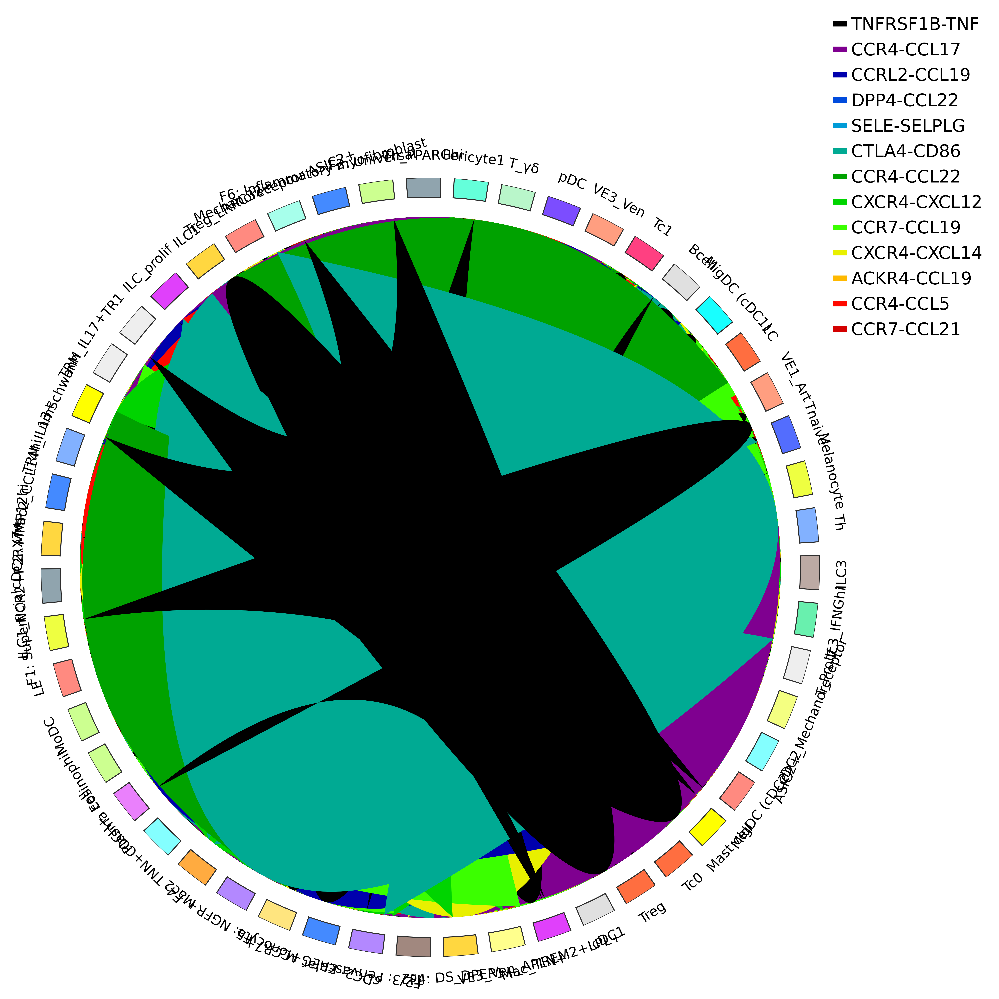

In [44]:
kpy.plot_cpdb_chord(
    adata=adata,
    #cell_type1="B cell",
    #cell_type2=".",
    means=means_subset,
    pvals=pvals_subset,
    deconvoluted=deconv,
    celltype_key="lvl5_annotation",
    cell_type1=".",
    cell_type2="."
    # interaction=['CXCL14_CXCR4', 'TNF_TNFRSF1B', 'IL4_IL4_receptor',
    #    'ICAM1_integrin_aMb2_complex', 'ICAM1_integrin_aXb2_complex',
    #    'CXCL12_CXCR4', 'TNFSF18_TNFRSF18', 'THY1_integrin_aXb2_complex',
    #    'THY1_integrin_aMb2_complex', 'CCL19_CCR7', 'CCL21_CCR7',
    #    'SELPLG_SELE', 'C3_integrin_aMb2_complex', 'CCL19_ACKR4',
    #    'CCL19_CCRL2', 'CD86_CTLA4', 'CCL22_CCR4', 'CCL22_DPP4',
    #    'CCL17_CCR4', 'CCL5_CCR4'],
    #link_kwargs={"direction": 1, "allow_twist": True, "r1": 95, "r2": 90},
   # sector_text_kwargs={"color": "black", "size": 12, "r": 105, "adjust_rotation": True},
  #  legend_kwargs={"loc": "center", "bbox_to_anchor": (1, 1), "fontsize": 8},
    #link_offset=1,
)

In [50]:
adata.obs.lvl5_annotation.value_counts()

lvl5_annotation
F2: Universal                     4460
F1: Superficial                   3022
VE3_Ven                           2743
F2/3: Perivascular                2308
Th                                2226
F3: FRC-like                      1996
Pericyte1                         1697
Mac2_CCL14hi                      1429
Mast cell                         1383
Melanocyte                        1322
Th_PPARGhi                        1215
LE                                1024
LC                                1003
cDC2: EREG+CCR7+                   895
F4: DS_DPEP1+                      890
Treg_LRRC32+                       866
cDC2: MMP12hi                      721
Tc2                                662
F4: TNN+COCH+                      644
Treg                               551
VE1_Art                            538
TRM_IL13+                          513
cDC1                               498
cDC2                               478
T_γδ                               432
Mac2     

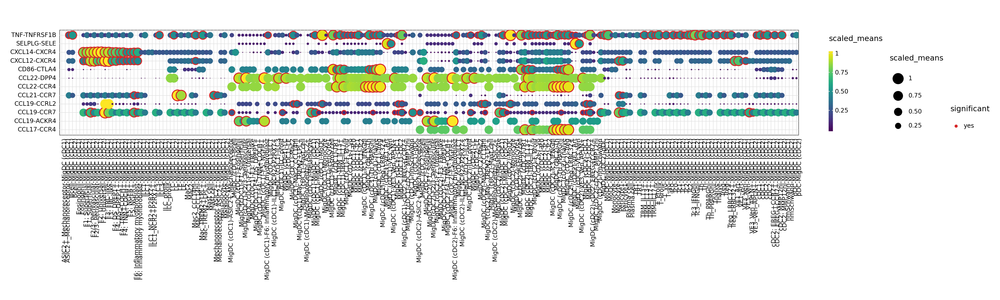

<Figure Size: (2000 x 600)>

In [45]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2= ".",
    # genes = [  "CCR3", "IL4", "OSM"],
    means=means_subset,
    pvals=pvals_subset,
    celltype_key="lvl5_annotation",
    highlight_size=.8,
    figsize=(20, 6),
    #save = "inflow_ccc.pdf"
)



In [53]:
sorted(adata.obs.lvl4_annotation.unique())

['ASIC2+_Mechanoreceptor',
 'Bcell',
 'Eosinophil',
 'F1: Superficial',
 'F2/3: Perivascular',
 'F2: Universal',
 'F3: FRC-like',
 'F4: DS_DPEP1+',
 'F4: TNN+COCH+',
 'F5: NGFR+',
 'F6: Inflammatory myofibroblast',
 'ILC1',
 'ILC1_NCR2+P2RX7+',
 'ILC3',
 'ILC_prolif',
 'LC',
 'LE',
 'Mac2',
 'Mac2_CCL14hi',
 'Mac_TREM2+LPL+',
 'Mast cell',
 'Mechanoreceptor ASIC2+',
 'Melanocyte',
 'MigDC (cDC1)',
 'MigDC (cDC2)',
 'MoDC',
 'Monocyte',
 'Pericyte1',
 'Plasma cell',
 'TR1',
 'TRM_IL13+',
 'TRM_IL17+',
 'T_Prolif',
 'T_γδ',
 'Tc0',
 'Tc1',
 'Tc2',
 'Tc3_IFNGhi',
 'Th',
 'Th_PPARGhi',
 'Tnaive',
 'Treg',
 'Treg_LRRC32+',
 'VE1_Art',
 'VE3_Ven',
 'VE3_Ven_APLN+',
 'cDC1',
 'cDC2',
 'cDC2: EREG+CCR7+',
 'cDC2: MMP12hi',
 'nmSchwann',
 'pDC']

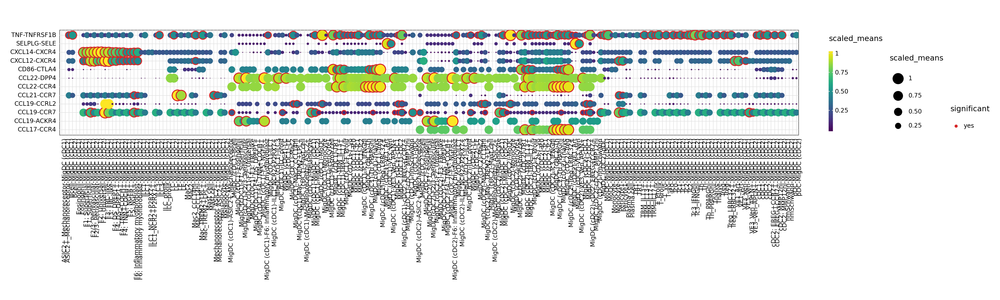

<Figure Size: (2000 x 600)>

In [49]:
p = kpy.plot_cpdb(
    adata        = adata,
    cell_type1   = "MigDC",
    cell_type2   = ".",           
    means        = means_subset,
    pvals        = pvals_subset,
    celltype_key = "lvl5_annotation",
    highlight_size = .8,
    figsize        = (20, 6),
)

p.save("inflow_ccc.pdf", width=20, height=6, dpi=300, verbose=False)
p      


[
    #'ASIC2+_Mechanoreceptor',
 'Bcell',
 #'Eosinophil',
 'F1: Superficial',
 'F2/3: Perivascular',
 'F2: Universal',
 'F3: FRC-like',
 #'F4: DS_DPEP1+',
 #'F4: TNN+COCH+',
 #'F5: NGFR+',
 #'F6: Inflammatory myofibroblast',
 'ILC1',
 #'ILC1_NCR2+P2RX7+',
 'ILC3',
 'ILC_prolif',
 #'LC',
 'LE',
 'Mac2',
 'Mac2_CCL14hi',
 #'Mac_TREM2+LPL+',
 'Mast cell',
# 'Mechanoreceptor ASIC2+',
# 'Melanocyte',
 #'MigDC (cDC1)',
 'MigDC (cDC2)',
 'MoDC',
 'Monocyte',
 'Pericyte1',
 'Plasma cell',
 #'TR1',
# 'TRM_IL13+',
# 'TRM_IL17+',
# 'T_Prolif',
## 'T_γδ',
 #'Tc0',
 ##'Tc1',
 #'Tc2',
 #'Tc3_IFNGhi',
 'Th',
 'Th_PPARGhi',
 'Tnaive',
 'Treg',
 #'Treg_LRRC32+',
# 'VE1_Art',
 'VE3_Ven',
 'VE3_Ven_APLN+',
 'cDC1',
 'cDC2',
 #'cDC2: EREG+CCR7+',
 'cDC2: MMP12hi',
 'nmSchwann',
 'pDC']

cell_type1 matches: ['MigDC (cDC1)', 'MigDC (cDC2)']
56 pairs kept


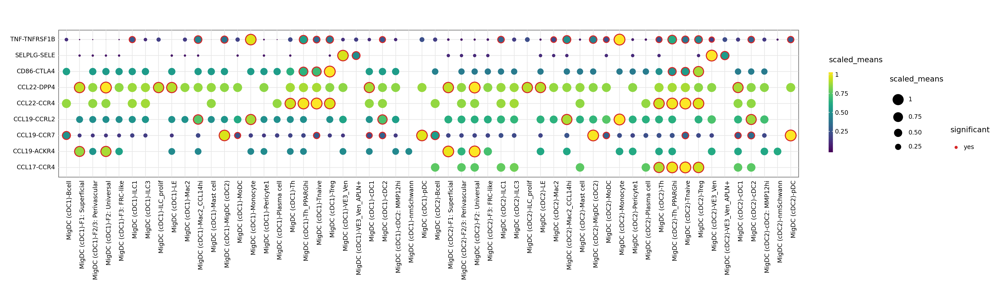

<Figure Size: (2000 x 600)>

In [54]:
partners = [
    'Bcell', 'F1: Superficial', 'F2/3: Perivascular', 'F2: Universal', 'F3: FRC-like',
    'ILC1', 'ILC3', 'ILC_prolif', 'LE', 'Mac2', 'Mac2_CCL14hi', 'Mast cell',
    'MigDC (cDC2)', 'MoDC', 'Monocyte', 'Pericyte1', 'Plasma cell',
    'Th', 'Th_PPARGhi', 'Tnaive', 'Treg',
    'VE3_Ven', 'VE3_Ven_APLN+', 'cDC1', 'cDC2', 'cDC2: MMP12hi', 'nmSchwann', 'pDC',
]

sep = "|"
info_cols = [c for c in means_subset.columns if sep not in c]          # interaction metadata
pair_cols = [c for c in means_subset.columns if sep in c]

ct1 = [c for c in sorted({p.split(sep)[0] for p in pair_cols}) if c.startswith("MigDC")]
print("cell_type1 matches:", ct1)                                       # check what "MigDC" covers

keep_pairs = [c for c in pair_cols
              if c.split(sep)[0] in ct1 and c.split(sep)[1] in set(partners)]
print(len(keep_pairs), "pairs kept")

m_plot = means_subset[info_cols + keep_pairs]
p_plot = pvals_subset[info_cols + keep_pairs]

p = kpy.plot_cpdb(
    adata        = adata,
    cell_type1   = "MigDC",
    cell_type2   = ".",
    means        = m_plot,
    pvals        = p_plot,
    celltype_key = "lvl5_annotation",
    highlight_size = .8,
    figsize        = (20, 6),
)

p.save("inflow_ccc.pdf", width=20, height=6, dpi=300, verbose=False)
p

In [47]:
# from cellphonedb.utils import search_utils

# search_results = search_utils.search_analysis_results(
#  #query_cell_types_1 = 'MigDC' ,  # List of cells 1, will be paired to cells 2 (list or 'All').
#    # query_cell_types_2 = ['T'],     # List of cells 2, will be paired to cells 1 (list or 'All').
#   #query_genes = ['IL33'],                                       # filter interactions based on the genes participating (list).
#  #   query_interactions = ['CSF1_CSF1R'],                            # filter intereactions based on their name (list).
#     significant_means = means,          # significant_means file generated by CellphoneDB.
#     deconvoluted = pvals,                    # devonvoluted file generated by CellphoneDB.
#     interaction_scores = interaction_scores,        # interaction score generated by CellphoneDB.
#     query_minimum_score = 1,                                       # minimum score that an interaction must have to be filtered.
#     separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
#     long_format = True,                                             # converts the output into a wide table, removing non-significant interactions
#    # query_classifications = ['Signaling by Transforming growth factor']
# )

# search_results.head(50)

,interacting_pair,partner_a,partner_b,gene_a,gene_b,directionality,classification,interacting_cells,significant_mean
0,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,Adhesion-Adhesion,Adhesion by Cadherin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
1,COL11A1_integrin_a2b1_complex,simple:P12107,complex:integrin_a2b1_complex,COL11A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
2,COL11A2_integrin_a2b1_complex,simple:P13942,complex:integrin_a2b1_complex,COL11A2,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
3,COL12A1_integrin_a2b1_complex,simple:Q99715,complex:integrin_a2b1_complex,COL12A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
4,COL13A1_integrin_a2b1_complex,simple:Q5TAT6,complex:integrin_a2b1_complex,COL13A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
5,COL14A1_integrin_a2b1_complex,simple:Q05707,complex:integrin_a2b1_complex,COL14A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
6,COL15A1_integrin_a2b1_complex,simple:P39059,complex:integrin_a2b1_complex,COL15A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
7,COL16A1_integrin_a2b1_complex,simple:Q07092,complex:integrin_a2b1_complex,COL16A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
8,COL17A1_integrin_a2b1_complex,simple:Q9UMD9,complex:integrin_a2b1_complex,COL17A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000
9,COL18A1_integrin_a2b1_complex,simple:P39060,complex:integrin_a2b1_complex,COL18A1,NaN,Adhesion-Adhesion,Adhesion by Collagen/Integrin,ASIC2+_Mechanoreceptor|ASIC2+_Mechanoreceptor,0.000


## 

In [48]:
STOP

NameError: name 'STOP' is not defined

In [ ]:
list(search_results["gene_a"])

In [ ]:
list(search_results["gene_b"])

In [ ]:
from cellphonedb.utils import search_utils

search_results = search_utils.search_analysis_results(
    query_cell_types_1 = [ "MigDC", "cDC2: MMP12+"],  # List of cells 1, will be paired to cells 2 (list or 'All').
    query_cell_types_2 = ['ILC2', 'ILC2_inflammatory'],     # List of cells 2, will be paired to cells 1 (list or 'All').
#   query_genes = ['CCL19'],                                       # filter interactions based on the genes participating (list).
 #   query_interactions = ['CSF1_CSF1R'],                            # filter intereactions based on their name (list).
    significant_means = cpdb_results['significant_means'],          # significant_means file generated by CellphoneDB.
    deconvoluted = cpdb_results['deconvoluted'],                    # devonvoluted file generated by CellphoneDB.
    interaction_scores = cpdb_results['interaction_scores'],        # interaction score generated by CellphoneDB.
    query_minimum_score = 50,                                       # minimum score that an interaction must have to be filtered.
    separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
    long_format = True,                                             # converts the output into a wide table, removing non-significant interactions
   # query_classifications = ['Signaling by Transforming growth factor']
)

search_results.head(50)

In [ ]:
list(search_results["gene_a"])

In [ ]:
list(search_results["gene_b"])

In [ ]:
from cellphonedb.utils import search_utils

search_results = search_utils.search_analysis_results(
    query_cell_types_1 = ['F3: CCL19+', ],  # List of cells 1, will be paired to cells 2 (list or 'All').
    query_cell_types_2 = ['Th', 'ILC2', 'ILC2_inflammatory', "Tc_IL13", "MigDC", "ILC1_3", "NK_ILC1"],     # List of cells 2, will be paired to cells 1 (list or 'All').
#   query_genes = ['CCL19'],                                       # filter interactions based on the genes participating (list).
 #   query_interactions = ['CSF1_CSF1R'],                            # filter intereactions based on their name (list).
    significant_means = cpdb_results['significant_means'],          # significant_means file generated by CellphoneDB.
    deconvoluted = cpdb_results['deconvoluted'],                    # devonvoluted file generated by CellphoneDB.
    interaction_scores = cpdb_results['interaction_scores'],        # interaction score generated by CellphoneDB.
    query_minimum_score = 50,                                       # minimum score that an interaction must have to be filtered.
    separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
    long_format = True,                                             # converts the output into a wide table, removing non-significant interactions
   # query_classifications = ['Signaling by Transforming growth factor']
)

search_results.head(50)

In [ ]:
search_results.tail(20)

In [ ]:
# cpdb_results.columns

In [ ]:
adata.obs["lvl3_annotation"].value_counts()

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2="Tc_IL13",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
)



In [ ]:
7

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg_LRRC32",
    cell_type2="MigDC",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
    scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)



In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg",
    cell_type2="MigDC",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
    scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)



In [ ]:
5

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg",
    cell_type2="Treg_LRRC32",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
    scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)



In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2="F3: FRC-like",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
    min_interaction_score=50,

)



In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2="Tnaive/Tcm",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
    scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)



In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="LC",
    cell_type2="ILC2",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
)


In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="LC",
    cell_type2="F3: CCL19+",
    means=means,
    pvals=pvals,
    celltype_key="lvl3_annotation",
    highlight_size=1,
    figsize=(20, 20),
)



In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Tc_IL17",
    cell_type2="F3: CCL19+",
    means=means,
    pvals=pvals,
    celltype_key="lvl3_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="VE3_SELPhi",
    cell_type2="ILC1_3",
    means=means,
    pvals=pvals,
    celltype_key="lvl3_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="VE3_SELPhi",
    cell_type2="ILC2",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=50,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2="ILC1_3",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg",
    cell_type2="Tc_IL13",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg",
    cell_type2="ILC1_3",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="Treg",
    cell_type2="Tc",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)

In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="MigDC",
    cell_type2="ILC2",
    means=means,
    pvals=pvals,
    celltype_key="lvl5_annotation",
    highlight_size=1,
    figsize=(20, 20),
        scale_alpha_by_interaction_scores=True,
    min_interaction_score=20,
)

In [ ]:
# kpy.plot_cpdb(
#     adata=adata,
#     cell_type1="MigDC",
#     cell_type2="G",
#     means=means,
#     pvals=pvals,
#     celltype_key="lvl3_annotation",
#     highlight_size=1,
#     figsize=(20, 20),
#         scale_alpha_by_interaction_scores=True,
#     min_interaction_score=20,
# )

In [ ]:
"TNFSF4", "TNFRSF4", 
"ADGRE5", "ITGAV" "ITGB1", "CD55", "LPAR2", "LPAR3",
"ITGA4", "ITGB1", "FN1", ""
"TNFSF14", "TNFRSF14", "TNFRSF6B",
"TNFSF12", "TNFRSF25"
"TNFSF10", "TNFRSF10A","TNFRSF10B","TNFRSF10D",
"SEMA4D","PTPRC",  "PLXNB2",
"SELPLG", "SELL", "PODXL",
"PTGES", ,"PTGES2", "PTGES3",  "PTGER4", "PTGER3", 
"PTGDS", "AKR1C3","PTGDR2","PTGDR3"
"LTC4S", "CYSLTR1", 
"AKR1B1", "PTGFR", 
"NECTIN2", "TIGIT", "CD226", "PVR", "CD96", 
"ALOX5", "LTC4S", "CTSLTR1", 
"LTB", "LTBR", "ICAM3", "ICAM2", "SIRPA", "SIRPG", "CD47", "ICAM1", "ITGAL","ITGB2",
"APP", "CD74", "CD44", "TYROBP",
"CCL5","CCL22", "CCL17", "CCR4","ACKR5", "DPP4",
"BAG6", "NCR3", 
"ALDH1A1", "RORB", "TGFB1", "TGFB2", "TGFBR3", "TNFSF12", "TNGRSF12A",   "TNFSF11", "TNGRSF11A", 
"NOTCH1", "DLL1", "DLL3", "JAG1", "NOTCH2", "CD46","CNTN1",
"CXCL2", "DPP4",
"RAMP3", "ADM",
"RAMP1", "CALCA",
"PLAUR", "PLAU", "ITGB1", "ITGA4", 

"VEGFB", "FLT1",
"CRLF2", "TSLP", "TSLPR",
"CXCL16", "CXCR6",
"CD58", "CD2", 
"KLRB2", "CLEC2D", 
"ENPTD1", "ADORA2A", "NT5E", "SLC19A1",
"AREG", "EGFR", 
"CD248", "IL6R", 
"COL3A1", "ADGRG1",
"IL34", "CSF1", "CSFR1", 
"CD320", "JAML",
"IGFBP3", "TMEM219",
"APP", "CD74", "SORL1",
"CD40LG", "ITGB1", "ITGA5",
"ICOS", "ICOSLG",
"WNT5B", "SFRP2", "SFRP1", "FRZB"
"GAS6", "AXL",
"CD1B", "IL6ST",
"CD200", "CD200R1", ""

In [ ]:
STOP

In [ ]:
kpy.plot_cpdb(
    adata = adata,
    cell_type1 =['F3: CCL19+', ],  
    cell_type2 =  [ "MigDC"],  
    genes = ["CCL19"],

    means = cpdb_results['means'],
    pvals = cpdb_results['pvalues'],
    celltype_key = "lvl3_annotation",
    figsize = (10, 3),
    title = " ",
    max_size = 3,
    highlight_size = 0.75,
    degs_analysis = False,
    standard_scale = True,
    interaction_scores = cpdb_results['interaction_scores'],
    scale_alpha_by_interaction_scores = True
)

# plots

In [ ]:
import ktplotspy as kpy


In [ ]:
relevant_interactions =  cpdb_results['pvalues']

In [ ]:
kpy.plot_cpdb_heatmap(pvals=relevant_interactions, degs_analysis=False, figsize=(15, 15), title="Sum of significant interactions")


In [ ]:
kpy.plot_cpdb(
    adata=adata,
    cell_type1="F3: CCL19+",
    cell_type2="MigDC",
    means=means,
    pvals=relevant_interactions,
    celltype_key="cell_labels",
    figsize=(7, 4),
    title="Interactions between\nPV and trophoblast with\ndownstream significance",
    max_size=6,
    highlight_size=0.75,
    degs_analysis=False,
    standard_scale=True,
   # cellsign=cellsign,
   # filter_by_cellsign=True,
)

In [ ]:
kpy.plot_cpdb_chord(
    adata=adata,
    cell_type1="F3: CCL19+",
    cell_type2="MigDC",
    means=means,
    pvals=pvals,
    deconvoluted=decon,
    celltype_key="lvl3_annotation",
    genes=["CCL19", "CCR7", "IL33"],
    figsize=(6, 6),
    labelposition=50,
)

In [ ]:
search_results.head(50)

In [ ]:
kpy.plot_cpdb_chord(
    adata=adata,
    cell_type1="F3: CCL19+",# "Pericyte1_CCL19+_signalling", "VE1_ADAMTS6hi", "VE3_SELPhi",],
    cell_type2= "ILC2",
    means=means,
    pvals=pvals,
    deconvoluted=deconv,
    celltype_key="lvl2_annotation",
    genes=["CCL19", "CCR7", "IL33",  'CD44', 'TYROBP', 'CXCL12', 'CXCR4', 'PTGDR2', "IL7", "IL7R", "CYSTLR2", "SELE" , "SELPLG", "CD200", "CD200R1"  ],
    figsize=(6, 6),
    labelposition=50,
)